# Домашняя работа 1


## Описание

В этой домашней работе вы должны применить знания по многослойным нейроным сетям

- Для простоты попробуем обучить сначала однослойный перцептрон
- Решать будем простую задачу бинарной классификации
- Датасет игрушечный -  `load_data()` загружает его


In [1]:
import numpy as np
import torch
from torch import nn
import sklearn
from sklearn.datasets import make_gaussian_quantiles
from sklearn.model_selection import train_test_split
from matplotlib.colors import ListedColormap
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader

## Загрузка данных

In [2]:
def load_data(n_samples=500):
    return make_gaussian_quantiles(
        mean=None,
        cov=0.7,
        n_samples=n_samples,
        n_features=2,
        n_classes=2,
        shuffle=True,
        random_state=42,
    )

In [3]:
gaussian_quantiles = load_data()
X, y = gaussian_quantiles

print(X[:10, :])
print(y[:10])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

[[-1.13773727  0.62436053]
 [-0.75970745 -1.18161805]
 [-0.82471758  0.42171557]
 [-0.09398039 -0.18487643]
 [-0.80731289  0.57399183]
 [ 0.67980788  1.13471182]
 [-1.70521733 -0.84342552]
 [ 1.57461467  1.12565917]
 [-0.22579357 -0.81889248]
 [ 0.97317262  0.00856159]]
[1 1 0 0 1 1 1 1 0 1]


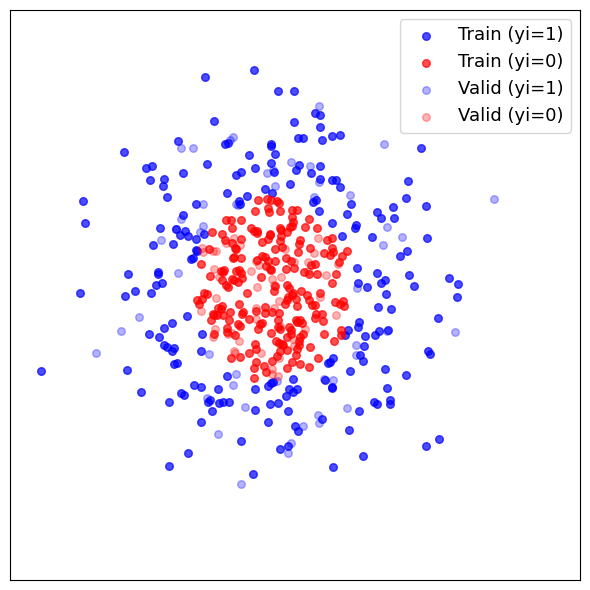

In [4]:
cm = plt.cm.RdBu
cm_bright = ListedColormap(['#FF0000', '#0000FF'])

def plot_data(X, y, xy_labels=True, label=None, **kwargs):
    X_1 = X[y == 1]
    X_0 = X[y == 0]
    if label is not None:
        plt.scatter(X_1[:, 0], X_1[:, 1], c="blue", s=30, label=label + " (yi=1)", **kwargs)
        plt.scatter(X_0[:, 0], X_0[:, 1], c="red", s=30, label=label + " (yi=0)", **kwargs)
    plt.xticks(())
    plt.yticks(())
    plt.xlim(X[:, 0].min() - 1, X[:, 0].max() + 1)
    plt.ylim(X[:, 1].min() - 1, X[:, 1].max() + 1)

plt.figure(figsize=(6, 6))
plot_data(X_train, y_train, alpha=0.7, label="Train")
plot_data(X_test, y_test, alpha=0.3, label="Valid")
plt.legend(fontsize=13)
plt.tight_layout()

## Класс нейросети

Вам необходимо описать простую полносвязную многослойную нейронную сеть

In [5]:
class NeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer1 = nn.Linear(2, 8)  # первый слой, Linear(колво ожидаемых признаков на вход, колво признаков на выход (длина вектора)), увеличивая размерность даем модели выучить новые признаки
        self.act1 = nn.ReLU()  # нужно, чтобы модель могла аппроксимировать сложные функции, благодаря ей сеть может выучивать сложные нелинейные зависимости
        self.layer2 = nn.Linear(8, 4)  # второй слой, уменьшая размерность, чтобы фильтровать, позволять оставаться только наиболее информативным признакам
        self.act2 = nn.ReLU()
        self.output = nn.Linear(4, 1)
        self.sigmoid = nn.Sigmoid()  # сигмоида превращает число в вероятность

    def forward(self, x):  # описано как вход превращается в выход
        x = self.act1(self.layer1(x))
        x = self.act2(self.layer2(x))
        x = self.sigmoid(self.output(x))
        return x


##  Функция обучения сети

Необходимо сохранять историю лоссов для последующего сравнения и визуализации.
Также нужно реализовать early stopping. Критерий остановки подбирите на ваше усмотрение.

In [6]:
import copy
import tqdm
import torch.optim as optim

def train(model, loss, opt,
          n_epochs, batch_size, lr,
          X_train, y_train,
          X_valid=None, y_valid=None,
          patience=30, min_delta=1e-4):  # patience определяет количество последовательных эпох (один полный проход модели по всему обучающему набору данных по батчам), в течение которых необходимо дождаться улучшения отслеживаемого показателя, прежде чем останавливать обучение; min_delta устанавливает минимальное изменение отслеживаемого показателя, которое считается улучшением, изменения, меньшие этого значения, игнорируются

    for param_group in opt.param_groups:  # перезаписывает скорость обучения в оптимизаторе тем значением lr, которое передаем в train (нужно, чтобы скорость обучения в оптимизаторе совпадала с той, что я передала в функцию)
        param_group['lr'] = lr

    batch_start = torch.arange(0, len(X_train), batch_size)   # индексы, с которых начинается каждый батч: 0, batch_size, 2*batch_size, ... : так потом удобно резать тензоры срезами X_train[start:start+batch_size]

    history = []  # сохраняем историю лоссов, средний loss на train после каждой эпохи
    valid_history = []  # loss (насколько предсказания отличаются от правильных ответов) на валидации после каждой эпохи

    # Hold the best model
    best_loss = np.inf  # для early stopping: если модель перестала улучшаться на валидации, значит она уже переобучается, и учить дальше нет смысла; лучший loss на валидации -  сначала бесконечность
    best_weights = None  # веса модели в лучшую эпоху
    epochs_without_improvement = 0  # счетчик плохих эпох подряд

    for epoch in range(n_epochs):
        model.train()
        epoch_loss = 0.0  # сумма ошибок за эпоху (в конце подилв на len(X_train) получим средний loss)
        with tqdm.tqdm(batch_start, unit="batch", mininterval=2, disable=False) as bar:
            bar.set_description(f"Epoch {epoch}")
            for start in bar:
                # take a batch
                X_batch = X_train[start:start+batch_size]  # берем батч (кусочек данных размера batch_size)
                y_batch = y_train[start:start+batch_size]
                # forward pass
                y_pred = model(X_batch)  # модель делает предсказания
                loss_value = loss(y_pred, y_batch)  # считет loss — насколько сильно ошиблась на этом батче
                # backward pass
                opt.zero_grad()  # если не обнулить старые градиенты, PyTorch будет их накапливать и шаг оптимизатора получится неправильным
                loss_value.backward()  # считаем новые градиенты для всех весов, после этого у каждого параметра будет свой .grad
                # update weights
                opt.step()  # двигаем веса по формуле: w_t = w_{t-1} - \alpha * \delta \mathcal{L}, где alpha - скорость обучения lr, а \delta \mathcal{L} - градиент
                # print progress
                epoch_loss += float(loss_value) * len(X_batch)  # loss_value — это средний лосс по батчу, поэтому надо умножить на len(X_batch) для суммы по всем объектам (чтобы потом усреднить по всей эпохе); у нас тензор, поэтому превращаем в float
                bar.set_postfix(loss=float(loss_value))  # показывает текущий лосс в полосочке прогресса

        history.append(epoch_loss / len(X_train))  # средний лосс за эпоху = сумма ошибок / число объектов

        if X_valid is not None:
            # evaluate loss at end of each epoch
            model.eval()                # режим проверки (переключает модель в режим eval)
            with torch.no_grad():       # без градиентов быстрее и экономится память
                valid_loss = float(loss(model(X_valid), y_valid))
            valid_history.append(valid_loss)

            if valid_loss < best_loss - min_delta:  # cxитаю улучшением только заметный сдвиг вниз (больше чем на min_delta), чтобы случайные колебания лосса не продлевали обучение бесконечно
                best_loss = valid_loss  # запоминаем улучшение
                best_weights = copy.deepcopy(model.state_dict())  # и копии весов, state_dict хранит ссылки на тензоры, поэтому используем copy.deepcopy
                epochs_without_improvement = 0
            else:
                epochs_without_improvement += 1  # если нет улучшения увеличиваем счетчик
                if epochs_without_improvement >= patience:  # собственно early_stopping: если подряд набралось patience плохих эпох останавливаем обучение и возвращаем лучшие запомненные веса
                    print(f"early stopping на эпохе {epoch + 1}, лучший valid loss = {best_loss:.4f}")
                    break

    # restore model (иначе она останется в той эпохе, на которой остановились, а та может быть уже переобученной)
    if best_weights is not None:
        model.load_state_dict(best_weights)

    return history, valid_history

### Обучите сеть

Обучите сеть три раза - с тремя разными оптимизиторами
Не забудьте переинициализировать сеть заного перед каждой загрузкой. Убедитесь, что вы верно передали параметры сети в оптимизатор

**Подсказка** Лучше объявить три независимых объекта - модель1, модель2 и модель3

In [7]:
X_train_torch = torch.from_numpy(X_train).float()
y_train_torch = torch.from_numpy(y_train).float().reshape(-1, 1)
X_valid_torch = torch.from_numpy(X_test).float()
y_valid_torch = torch.from_numpy(y_test).float().reshape(-1, 1)

loss_fn = nn.BCELoss()  # binary cross entropy: функция потерь nn.BCELoss(), она сильно штрафует, когда модель уверена, а ошибается, формула: L = -[y·log(p) + (1-y)·log(1-p)]
n_epochs = 300  # number of epochs to run, максимум эпох (раньше может остановить early stopping)
batch_size = 32  # size of each batch (сколько примеров в одном батче)

model1 = NeuralNetwork()   # для SGD, SGD самый простой: просто шагаем против градиента по формуле выше
model2 = NeuralNetwork()   # для Adam, Adam умнее: для каждого веса сам подбирает размер шага и помнит, куда двигался раньше (инерция)
model3 = NeuralNetwork()   # для RMSProp, RMSprop уменьшает шаг для весов, у которых градиенты были большими

start_weights = copy.deepcopy(model1.state_dict())  # делаем стартовые веса одинаковыми: копируем веса первой модели в остальные (три модели — это три независимых объекта, у каждого свои веса, делаем их одинаковыми, иначе нельзя будет понять, чем отличаются результаты - оптимизатором или просто удачным началом)
model2.load_state_dict(start_weights)
model3.load_state_dict(start_weights)

lrs = {'SGD': 0.1, 'Adam': 0.01, 'RMSProp': 0.01}   # скорость обучения для каждого оптимизатора: SGD делает маленькие шаги по градиенту, ему можно lr побольше; Adam и RMSprop сами адаптируют шаг под каждый вес, поэтому их lr обычно в 10-100 раз меньше

optims = {
    'SGD': optim.SGD(model1.parameters(), lr=lrs['SGD']),
    'Adam': optim.Adam(model2.parameters(), lr=lrs['Adam']),
    'RMSProp': optim.RMSprop(model3.parameters(), lr=lrs['RMSProp']),
}

models = {'SGD': model1, 'Adam': model2, 'RMSProp': model3}

histories = {}  # сюда будем класть истории лоссов каждого оптимизатора

for opt_name, opt in optims.items():
    histories[opt_name] = train(
        model=models[opt_name],
        loss=loss_fn,
        opt=opt,
        n_epochs=n_epochs,
        batch_size=batch_size,
        lr=lrs[opt_name],
        X_train=X_train_torch,
        y_train=y_train_torch,
        X_valid=X_valid_torch,
        y_valid=y_valid_torch)

loss_SGD = histories['SGD'][0]
loss_Adam = histories['Adam'][0]
loss_rmsprop = histories['RMSProp'][0]

Epoch 0:   0%|          | 0/13 [00:00<?, ?batch/s]/tmp/ipykernel_41681/1904768265.py:42: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  epoch_loss += float(loss_value) * len(X_batch)  # loss_value — это средний лосс по батчу, поэтому надо умножить на len(X_batch) для суммы по всем объектам (чтобы потом усреднить по всей эпохе); у нас тензор, поэтому превращаем в float
Epoch 237: 100%|██████████| 13/13 [00:00<00:00, 432.49batch/s, loss=0.0176]

early stopping на эпохе 238, лучший valid loss = 0.0221


### А теперь посмотрим на графики лоссов

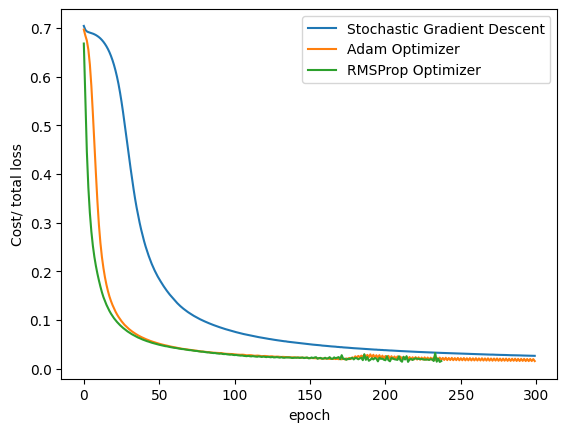

In [8]:
plt.plot(loss_SGD, label = "Stochastic Gradient Descent")
plt.plot(loss_Adam, label = "Adam Optimizer")
plt.plot(loss_rmsprop, label = 'RMSProp Optimizer')
plt.xlabel('epoch')
plt.ylabel('Cost/ total loss')
plt.legend()
plt.show()

# чем ниже кривая и чем быстрее она падает, тем лучше оптимизатор справляется с задачей. Кривые разной длины — это early stopping: тот, кто быстрее дошел до плато, остановился раньше

In [9]:
for name, (train_hist, valid_hist) in histories.items():
    print(f'{name:8s} | train loss: first={train_hist[0]:.4f}  '
          f'last={train_hist[-1]:.4f}  min={min(train_hist):.4f} | '
          f'valid last={valid_hist[-1]:.4f}')

# для этого запуска все три оптимизатора успешно обучили сеть (train-loss c ~ 0.6-0.07 (first) до 0.02-0.2 (last)), модели действительно выучили закономерность в данных, а не просто запомнили ответы. У Adam лучший результат, но при  запусках это может измениться, у RMSprop наибольший разрыв train/valid (0.023 → 0.070) - признак менее устойчивой сходимости

SGD      | train loss: first=0.7041  last=0.0261  min=0.0261 | valid last=0.0338
Adam     | train loss: first=0.6966  last=0.0153  min=0.0153 | valid last=0.0229
RMSProp  | train loss: first=0.6679  last=0.0154  min=0.0136 | valid last=0.0337


[-0.01129259 -0.88494444] -> [0.00326604] (expected [0.])
[-0.5543908   0.47739708] -> [7.4466266e-11] (expected [0.])
[-0.82118905  0.3866235 ] -> [0.3129646] (expected [0.])
[-0.44364536 -0.663365  ] -> [1.6758289e-06] (expected [0.])
[ 0.06473097 -0.72060204] -> [9.763788e-12] (expected [0.])


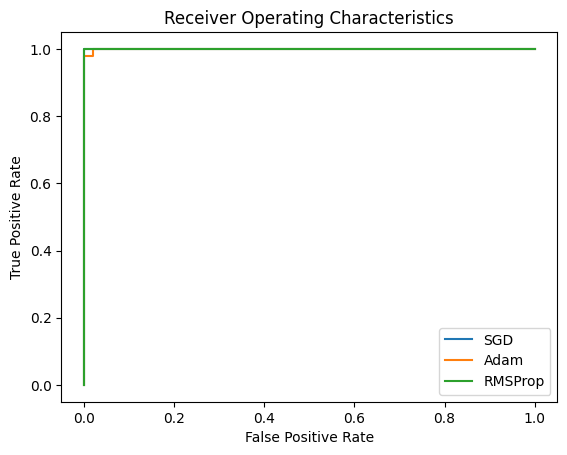

In [12]:
from sklearn.metrics import roc_curve

model = models['Adam']
model.eval()
with torch.no_grad():
    # Test out inference with 5 samples
    for i in range(5):
        y_pred = model(X_valid_torch[i:i+1])
        print(f"{X_valid_torch[i].numpy()} -> {y_pred[0].numpy()} (expected {y_valid_torch[i].numpy()})")

    for name, m in models.items():
        m.eval()
        fpr, tpr, thresholds = roc_curve(y_valid_torch, m(X_valid_torch))
        plt.plot(fpr, tpr, label=name)   # ROC curve = TPR vs FPR
    plt.title("Receiver Operating Characteristics")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend()
    plt.show()

# ROC-кривая показывает, насколько хорошо модель умеет отделять классы, независимо от выбранного порога вероятности
# По оси X лежит доля «ложных тревог» (FPR): объекты класса 0, ошибочно названные классом 1. По оси Y лежит доля найденных объектов класса 1 (TPR). Диагональ означает угадывание наугад. Чем ближе кривая к левому верхнему углу, тем лучше сеть отделяет классы. Качество всей кривой одним числом показывает AUC: 1.0 идеально, 0.5 как случайно.
# По ROC-кривым все три модели работают почти идеально: у RMSprop и SGD кривая идёт по левой и верхней сторонам квадрата (AUC = 1.0), а у Adam есть маленькая ступенька в левом верхнем углу (AUC тоже почти 1), то есть он ошибся буквально на одной паре точек, поэтому по этому графику разница между оптимизаторами почти не видна

## (Почти) Боевая задача

Перед вами датасет с классификацией алкоголя. Продемонстрируйте свои знания и решите задачу многоклассовой классификации

In [13]:
df = sklearn.datasets.load_wine(as_frame=True)
df = df.frame
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [14]:
print(df.shape)
print(df['target'].value_counts().sort_index())   # смотрим сколько вин каждого сорта (нам нужно по 13 характеристикам вина определить один из трех сортов)

(178, 14)
target
0    59
1    71
2    48
Name: count, dtype: int64


In [15]:
from sklearn.preprocessing import StandardScaler

X_wine = df.drop('target', axis=1).values  # отделяем признаки
y_wine = df['target'].values  # от ответов

# делим на трейн и тест, отделяем тест (20 процентов инфы) и валид (еще 20 из оставшегося)
X_temp, X_wine_test, y_temp, y_wine_test = train_test_split(X_wine, y_wine, test_size=0.2, shuffle=True, stratify=y_wine)   # stratify=y_wine гарантирует, что в train и test будет пропорциональное количество каждого класса
X_wine_train, X_wine_valid, y_wine_train, y_wine_valid = train_test_split(X_temp, y_temp, test_size=0.2, shuffle=True, stratify=y_temp)

scaler = StandardScaler()  # нормализируем данные (они разного масштаба)
scaler.fit(X_wine_train)  # fit надо делать только на трейн, чтобы не было утечки данных
X_wine_train = scaler.transform(X_wine_train)
X_wine_valid = scaler.transform(X_wine_valid)
X_wine_test = scaler.transform(X_wine_test)

X_train_torch = torch.tensor(X_wine_train, dtype=torch.float32)  # переводим все в тензоры
X_valid_torch = torch.tensor(X_wine_valid, dtype=torch.float32)
X_test_torch = torch.tensor(X_wine_test, dtype=torch.float32)

y_train_torch = torch.tensor(y_wine_train, dtype=torch.long)   # номера классов это целые числа
y_valid_torch = torch.tensor(y_wine_valid, dtype=torch.long)
y_test_torch = torch.tensor(y_wine_test, dtype=torch.long)

print(X_train_torch.shape, X_valid_torch.shape, X_test_torch.shape)

torch.Size([113, 13]) torch.Size([29, 13]) torch.Size([36, 13])


In [16]:
# класс нейросети, описываем ее

class WineClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer1 = nn.Linear(13, 32)  # на входе у нас 13 признаков, поэтому и начинаем с 13
        self.act1 = nn.ReLU()  # нужно, чтобы модель могла аппроксимировать сложные функции, благодаря ей сеть может выучивать сложные нелинейные зависимости
        self.layer2 = nn.Linear(32, 16)  # второй слой, уменьшая размерность, чтобы фильтровать, позволять оставаться только наиболее информативным признакам
        self.act2 = nn.ReLU()
        self.output = nn.Linear(16, 3)  # на выходе 3 сорта вина

    def forward(self, x):  # описано как вход превращается в выход
        x = self.act1(self.layer1(x))
        x = self.act2(self.layer2(x))
        x = self.output(x)
        return x

In [17]:
# функция обучения сети

def train(model, loss_fn, opt,
          n_epochs, batch_size,
          X_train, y_train,
          X_valid=None, y_valid=None):

    batch_start = torch.arange(0, len(X_train), batch_size)

    history = []        # трейн лосс по эпохам
    valid_history = []  # валид лосс по эпохам
    acc_history = []    # валид аккьюраси по эпохам

    best_val_loss = np.inf
    best_weights = None

    for epoch in range(n_epochs):
        model.train()
        epoch_loss = 0.0

        with tqdm.tqdm(batch_start, unit="batch", mininterval=0, disable=False) as bar:
            bar.set_description(f"Epoch {epoch}")
            for start in bar:
                # take a batch
                X_batch = X_train[start:start+batch_size]
                y_batch = y_train[start:start+batch_size]
                # forward pass
                y_pred = model(X_batch)
                loss = loss_fn(y_pred, y_batch)  # в CrossEntropy y_pred первым
                # backward pass
                opt.zero_grad()
                loss.backward()
                # update weights
                opt.step()
                epoch_loss += loss.item() * len(X_batch)  # накапливаем лосс
                bar.set_postfix(loss=float(loss))

        history.append(epoch_loss / len(X_train))  # средний трейн лосс за эпоху

        if X_valid is not None:
          # evaluate at end of each epoch
            model.eval()
            with torch.no_grad():
                val_logits = model(X_valid)
                val_loss = float(loss_fn(val_logits, y_valid))
                val_acc = (val_logits.argmax(dim=1) == y_valid).float().mean().item()

            valid_history.append(val_loss)
            acc_history.append(val_acc)

            if val_loss < best_val_loss:  # early stopping: запоминаем лучшие веса
                best_val_loss = val_loss
                best_weights = copy.deepcopy(model.state_dict())

    # restore best model (иначе она останется в той эпохе, на которой остановились, а та может быть уже переобученной)
    if best_weights is not None:
        model.load_state_dict(best_weights)

    return history, valid_history, acc_history

In [18]:
wine_model = WineClassifier()
loss_fn = nn.CrossEntropyLoss()  # используем CrossEntropyLoss для многоклассовой задачи
opt = optim.Adam(wine_model.parameters(), lr=0.001)

history, valid_history, acc_history = train(
    wine_model, loss_fn, opt,
    n_epochs=100, batch_size=16,
    X_train=X_train_torch, y_train=y_train_torch,
    X_valid=X_valid_torch, y_valid=y_valid_torch
)

Epoch 99: 100%|██████████| 8/8 [00:00<00:00, 210.60batch/s, loss=0.000816]


In [19]:
# cчитаем итоговую точность на тесте

wine_model.eval()
with torch.no_grad():
    test_logits = wine_model(X_test_torch)
    test_acc = (test_logits.argmax(dim=1) == y_test_torch).float().mean().item()
    test_loss = float(loss_fn(test_logits, y_test_torch))

print(f"TEST: loss={test_loss:.4f}, accuracy={test_acc*100:.2f}%")

TEST: loss=0.2449, accuracy=88.89%


TEST: loss=0.2449, accuracy=88.89%


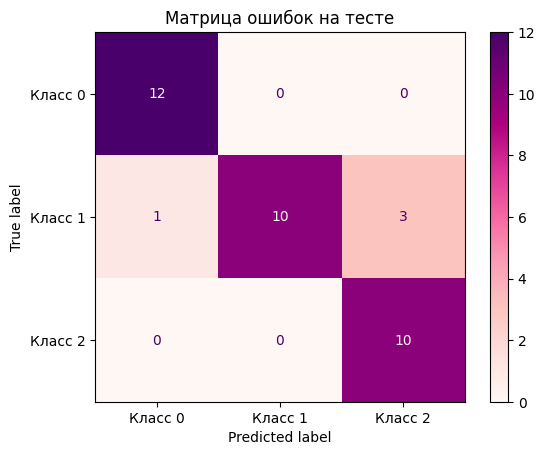

In [25]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 1. Считаем итоговую точность на тесте
wine_model.eval()
with torch.no_grad():
    test_logits = wine_model(X_test_torch)
    test_acc = (test_logits.argmax(dim=1) == y_test_torch).float().mean().item()
    test_loss = float(loss_fn(test_logits, y_test_torch))

print(f"TEST: loss={test_loss:.4f}, accuracy={test_acc*100:.2f}%")

# строим матрицу ошибок для оценки модели (чтобы видеть, какие классы путаются) (мне это иишка посоветовала, потому что ROC-кривые строятся для бинарной классификации (двух классов, у нас три (сорта вина)))
with torch.no_grad():
    test_pred = wine_model(X_test_torch).argmax(dim=1).numpy()

cm = confusion_matrix(y_test_torch.numpy(), test_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Класс 0', 'Класс 1', 'Класс 2'])
disp.plot(cmap='RdPu')
plt.title('Матрица ошибок на тесте')
plt.show()

# в данном запуске матрица ошибок показала, что модель идеально распознает класс 0 (12 из 12) и класс 2 (10 из 10), но иногда путает класс 1 с классом 2 (3 ошибки) и один раз перепутала класс 1 с классом 0
# значит, сорта вин 1 и 2 похожи по характеристикам, и нам стоило бы добавить новые признаки или больше данных для этих классов, чтобы сеть научилась их точнее различать